In [16]:
import numpy as np
import pandas as pd
import collections
%matplotlib inline

In [19]:
class FungusClassifier(object):
    """Infers a hidden variable and uses Bayesian classification to predict whether a fungus is 
    edible or poisonous"""
    def __init__(self,filename):
        data=pd.read_csv('mushrooms.csv')
        clusters=[]
        for (i,row) in data.iterrows():
            best=-1
            sim=0.5
            for (j,cluster) in enumerate(clusters):
                x=sum(cluster[key][value]/sum(cluster[key].values())
                      for (key,value) in row.iteritems())/(data.shape[1])
                if x>sim:
                    best=j
                    sim=x
                    
            if best==-1:
                clusters.append(collections.defaultdict(lambda: collections.defaultdict(float)))
                print(i+1,'rows analysed',len(clusters),'clusters found')
            for (key,value) in row.iteritems():
                clusters[best][key][value]+=1.0
        index=[]
        for column in data.columns:
            index.extend([(column,value) for value in data[column].unique()])
        self.probabilities=pd.DataFrame({(key,value):[cluster[key][value]+1.0 for cluster in clusters]
                                            for (key,value) in index}).T
        self.prior=self.probabilities.sum(axis=0)
        self.prior/=self.prior.sum()
        self.edibility_prior=self.probabilities.loc['class'].sum(axis=1)
        self.edibility_prior/=self.edibility_prior.sum()
        def normalize(group):
            return group.div(group.sum(axis=0),axis='columns')
        self.probabilities=self.probabilities.groupby(axis=0,level=0).apply(normalize)
        
    def __call__(self,**kwargs):
        "Estimates the probability that a fungus is edible given the features in kwargs"
        category=self.prior.copy()
        for (key,value) in kwargs.items():
            category*=self.probabilities.loc[(key,value)]
            category/=category.sum()
        result=self.edibility_prior*((self.probabilities.loc['class']*category).sum(axis=1))
        return result/result.sum()
    
    def test(self,filename):
        """Produces KDE plots of the estimated probability"""
        data=pd.read_csv(filename,index_col=False)
        observables=[column for column in data.columns if column!='class']
        results=pd.DataFrame([self(**row) for (i,row) in data[observables].iterrows()])
        results.loc[:,'class']=data['class']
        return results

In [20]:
BBN=FungusClassifier('mushrooms.csv')

1 rows analysed 1 clusters found
15 rows analysed 2 clusters found
1817 rows analysed 3 clusters found
3985 rows analysed 4 clusters found
4024 rows analysed 5 clusters found
4077 rows analysed 6 clusters found
4195 rows analysed 7 clusters found
6039 rows analysed 8 clusters found
6416 rows analysed 9 clusters found
6913 rows analysed 10 clusters found
6968 rows analysed 11 clusters found


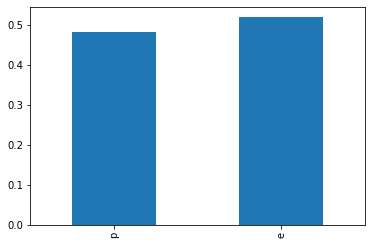

In [21]:
BBN.edibility_prior.plot.bar()

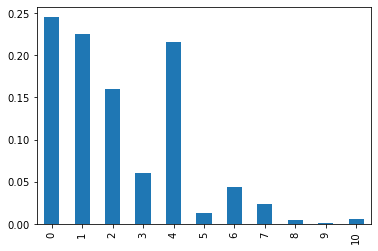

In [22]:
BBN.prior.plot.bar()

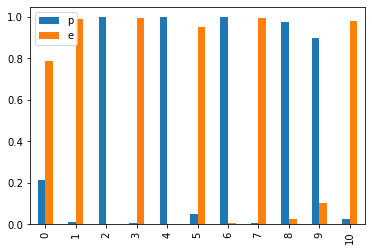

In [23]:
BBN.probabilities.loc['class'].T.plot.bar()

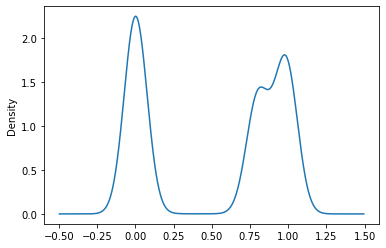

In [24]:
result=BBN.test('mushrooms.csv')
result['e'].plot.kde()

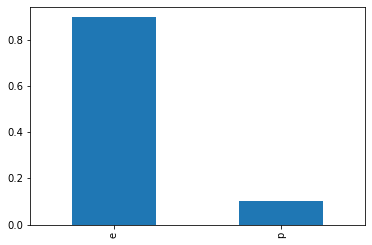

In [25]:
result[result['e']>0.5]['class'].value_counts(normalize=True).plot.bar()

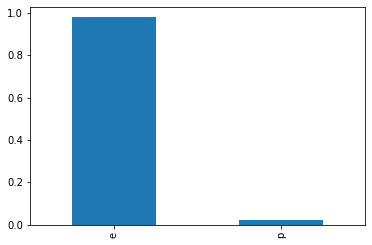

In [26]:
result[result['e']>0.9]['class'].value_counts(normalize=True).plot.bar()